# ML Lab Assignment 4
# Taneesha Badhe, Panel C, 1032232190

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix,
                              classification_report, mean_squared_error)

In [2]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target
print('First 10 rows:')
print(df.head(10))
print('\nDataset shape:', df.shape)
print('\nTarget classes:', cancer.target_names)

First 10 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   
5        12.45         15.70           82.57      477.1          0.12780   
6        18.25         19.98          119.60     1040.0          0.09463   
7        13.71         20.83           90.20      577.9          0.11890   
8        13.00         21.82           87.50      519.8          0.12730   
9        12.46         24.04           83.97      475.9          0.11860   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760         0.30010              0.14710         0.2419  

In [5]:
print('Statistical Summary:')
print(df.describe())
print('\nMissing Values:')
print(df.isnull().sum())
print('\nClass Distribution:')
print(df['target'].value_counts())

Statistical Summary:
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             

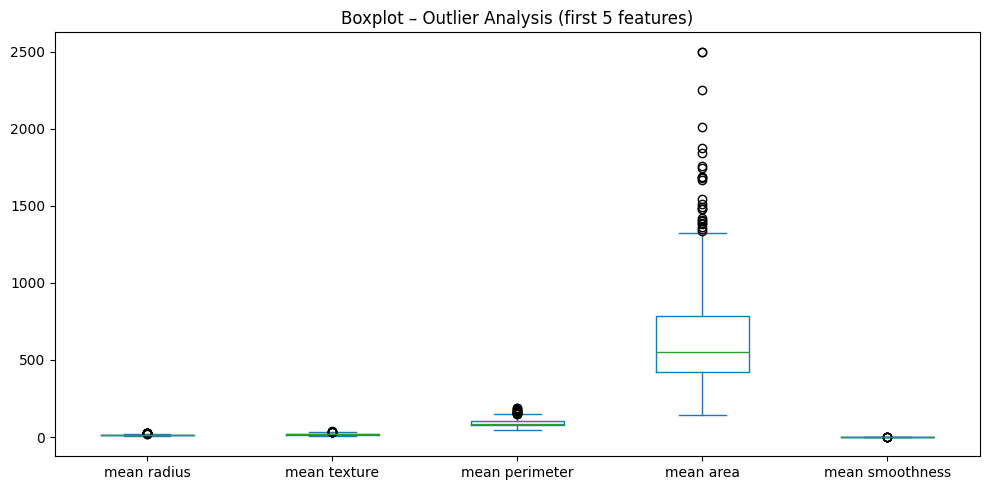

In [6]:
# Boxplot for first 5 features to check outliers
df[cancer.feature_names[:5]].plot(kind='box', figsize=(10, 5))
plt.title('Boxplot – Outlier Analysis (first 5 features)')
plt.tight_layout()
plt.show()

In [7]:
# Breast cancer dataset has no missing values
# In a real dataset: df.fillna(df.mean(), inplace=True)
print('Total missing values:', df.isnull().sum().sum())

Total missing values: 0


In [8]:
X = df[cancer.feature_names].values
y = df['target'].values
print('Features (X) shape:', X.shape)
print('Target  (y) shape :', y.shape)

Features (X) shape: (569, 30)
Target  (y) shape : (569,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print('Train size:', X_train.shape)
print('Test size :', X_test.shape)

Train size: (455, 30)
Test size : (114, 30)


In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)
print('Standardization done.')

Standardization done.


In [11]:
svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print('=== SVM Results ===')
print('Accuracy :', accuracy_score(y_test, svm_pred))
print('MSE      :', mean_squared_error(y_test, svm_pred))
print('\nConfusion Matrix:')
print(confusion_matrix(y_test, svm_pred))
print('\nClassification Report:')
print(classification_report(y_test, svm_pred, target_names=cancer.target_names))

=== SVM Results ===
Accuracy : 0.9824561403508771
MSE      : 0.017543859649122806

Confusion Matrix:
[[41  2]
 [ 0 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [12]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

print('=== Decision Tree Results ===')
print('Accuracy :', accuracy_score(y_test, dt_pred))
print('MSE      :', mean_squared_error(y_test, dt_pred))
print('\nConfusion Matrix:')
print(confusion_matrix(y_test, dt_pred))
print('\nClassification Report:')
print(classification_report(y_test, dt_pred, target_names=cancer.target_names))

=== Decision Tree Results ===
Accuracy : 0.9473684210526315
MSE      : 0.05263157894736842

Confusion Matrix:
[[40  3]
 [ 3 68]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [13]:
svm_acc = accuracy_score(y_test, svm_pred)
dt_acc  = accuracy_score(y_test, dt_pred)
svm_mse = mean_squared_error(y_test, svm_pred)
dt_mse  = mean_squared_error(y_test, dt_pred)

print('--- Performance Comparison ---')
print(f'{'Model':20s} {'Accuracy':>10s} {'MSE':>10s}')
print(f'{'SVM (RBF kernel)':20s} {svm_acc:>10.4f} {svm_mse:>10.4f}')
print(f'{'Decision Tree':20s} {dt_acc:>10.4f} {dt_mse:>10.4f}')

# Bar chart
models = ['SVM', 'Decision Tree']
accuracies = [svm_acc, dt_acc]
mse_vals   = [svm_mse, dt_mse]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(models, accuracies, color=['steelblue', 'seagreen'])
axes[0].set_title('Accuracy Comparison')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim(0.8, 1.05)
for i, v in enumerate(accuracies):
    axes[0].text(i, v + 0.005, f'{v:.4f}', ha='center')

axes[1].bar(models, mse_vals, color=['tomato', 'orange'])
axes[1].set_title('MSE Comparison')
axes[1].set_ylabel('Mean Squared Error')
for i, v in enumerate(mse_vals):
    axes[1].text(i, v + 0.002, f'{v:.4f}', ha='center')

plt.tight_layout()
plt.show()

SyntaxError: f-string: expecting '}' (3199688203.py, line 7)

In [14]:
label_map = {0: 'malignant', 1: 'benign'}
print('Sample Predictions (first 5 test samples):')
print(f'{'Sample':>8s}  {'SVM Pred':>12s}  {'DT Pred':>12s}  {'Actual':>12s}')
for i in range(5):
    print(f'{i+1:>8d}  {label_map[svm_pred[i]]:>12s}  '
          f'{label_map[dt_pred[i]]:>12s}  {label_map[y_test[i]]:>12s}')

SyntaxError: f-string: expecting '}' (3174950088.py, line 3)